Saving original_dataset.csv to original_dataset.csv
Dataset Shape: (20000, 22)


,age,gender,marital_status,education_level,annual_income,monthly_income,employment_status,debt_to_income_ratio,credit_score,loan_amount,...,loan_term,installment,grade_subgrade,num_of_open_accounts,total_credit_limit,current_balance,delinquency_history,public_records,num_of_delinquencies,loan_paid_back
0,59,Male,Married,Master's,24240.19,2020.02,Employed,0.074,743,17173.72,...,36,581.88,B5,7,40833.47,24302.07,1,0,1,1
1,72,Female,Married,Bachelor's,20172.98,1681.08,Employed,0.219,531,22663.89,...,60,573.17,F1,5,27968.01,10803.01,1,0,3,1
2,49,Female,Single,High School,26181.80,2181.82,Employed,0.234,779,3631.36,...,60,76.32,B4,2,15502.25,4505.44,0,0,0,1
3,35,Female,Single,High School,11873.84,989.49,Employed,0.264,809,14939.23,...,36,468.07,A5,7,18157.79,5525.63,4,0,5,1
4,63,Other,Single,Other,25326.44,2110.54,Employed,0.260,663,16551.71,...,60,395.50,D5,1,17467.56,3593.91,2,0,2,1



Missing Values: 0
Duplicate Rows: 0

After Cleaning:
Shape: (20000, 22)
Missing Values: 0
Duplicates: 0

Target Distribution:
loan_paid_back
1    15998
0     4002
Name: count, dtype: int64


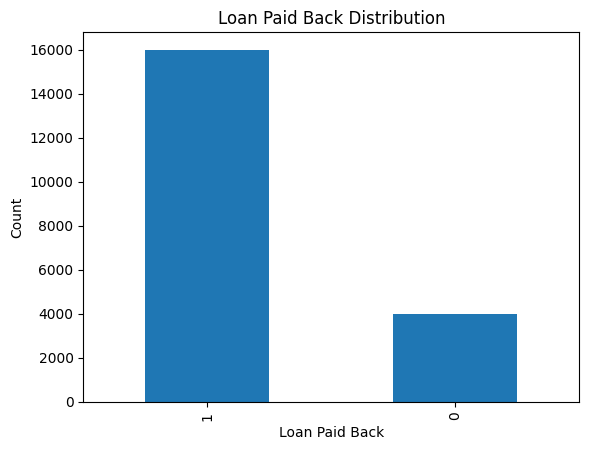

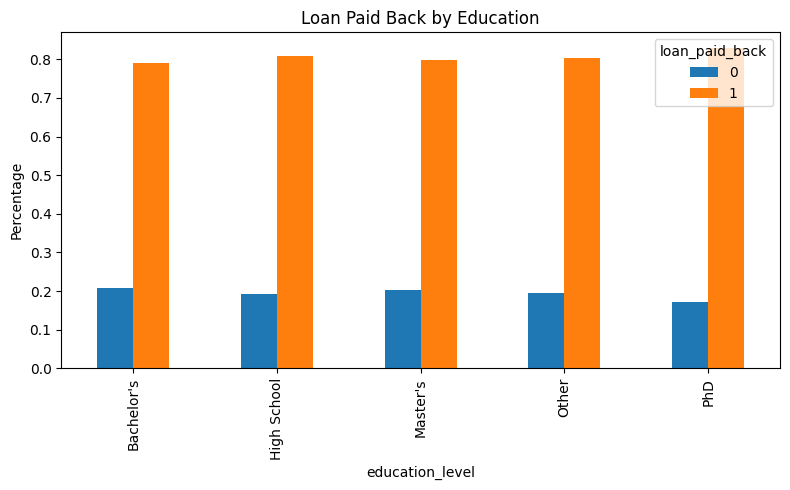

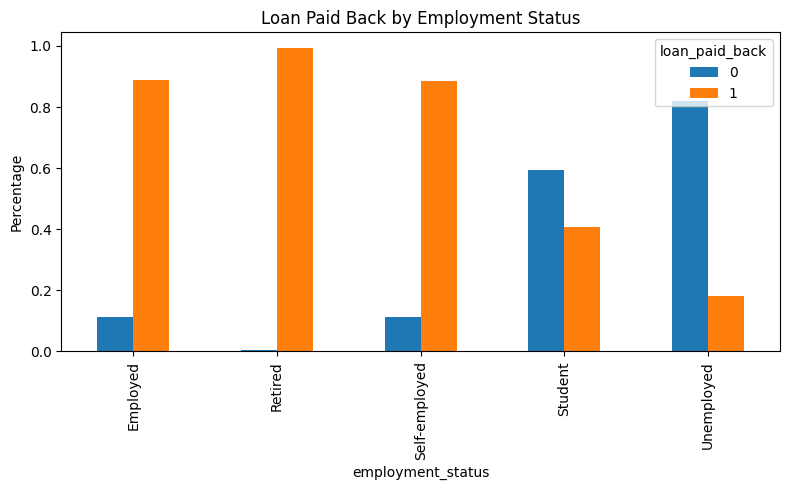

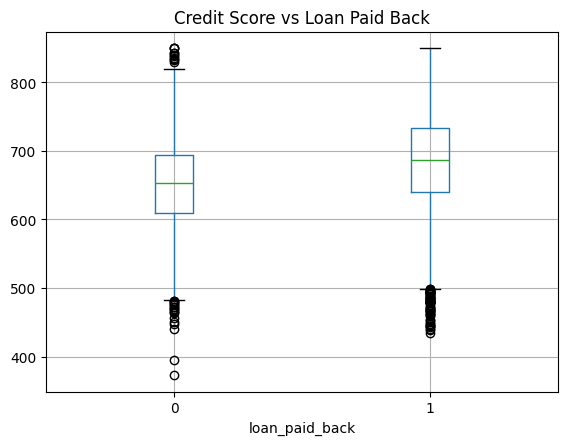

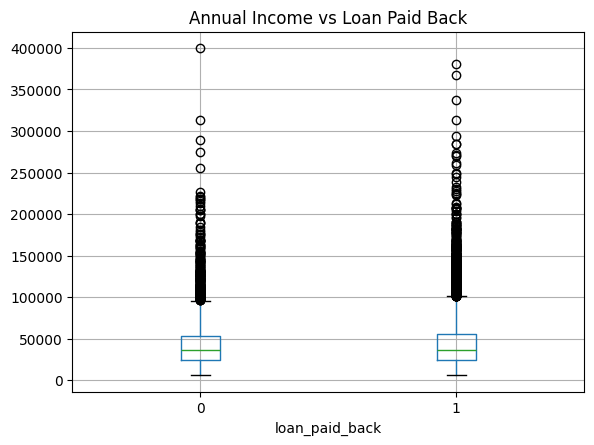

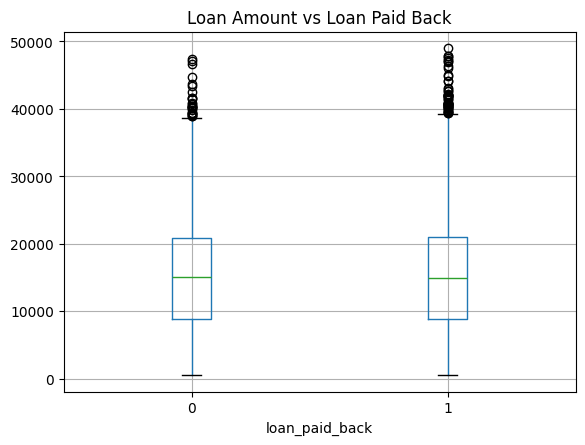


Correlation with Target:
loan_paid_back          1.000000
credit_score            0.199841
age                     0.007999
public_records          0.003210
monthly_income          0.003057
annual_income           0.003057
num_of_open_accounts    0.002964
loan_amount            -0.002490
loan_term              -0.002615
total_credit_limit     -0.002985
current_balance        -0.004749
installment            -0.010068
num_of_delinquencies   -0.070896
delinquency_history    -0.084940
interest_rate          -0.110935
debt_to_income_ratio   -0.223831
Name: loan_paid_back, dtype: float64


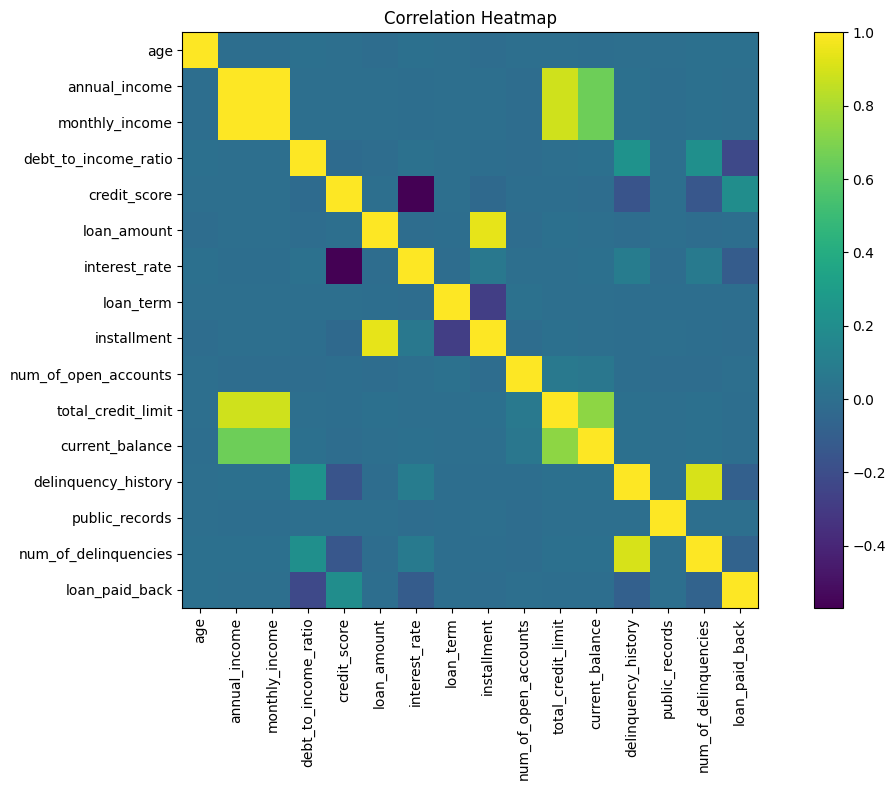


========== MODEL RESULTS ==========
Accuracy  : 88.67%
Precision : 90.08%
Recall    : 96.47%
F1 Score  : 93.16%

Classification Report:
              precision    recall  f1-score   support

           0       0.80      0.57      0.67       800
           1       0.90      0.96      0.93      3200

    accuracy                           0.89      4000
   macro avg       0.85      0.77      0.80      4000
weighted avg       0.88      0.89      0.88      4000


Confusion Matrix:
[[ 460  340]
 [ 113 3087]]


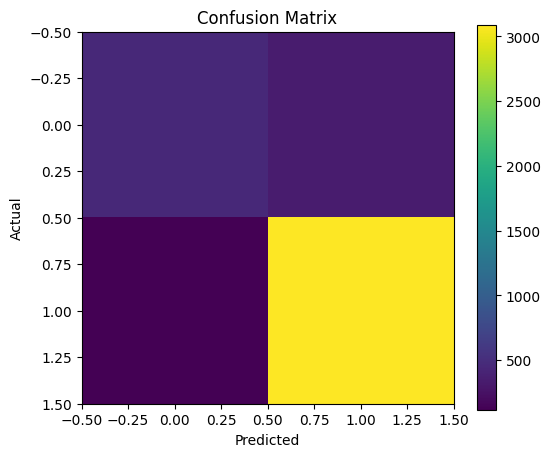


Cleaned dataset saved successfully!
PROJECT COMPLETED SUCCESSFULLY


In [1]:
# ============================================================
# LOAN PREDICTION ANALYSIS - DAE PROJECT
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt
from google.colab import files

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, classification_report
)

# 1. UPLOAD & LOAD DATASET
uploaded = files.upload()
file = list(uploaded.keys())[0]
df = pd.read_csv(file)

print("Dataset Shape:", df.shape)
display(df.head())

# 2. DATA INSPECTION
print("\nMissing Values:", df.isnull().sum().sum())
print("Duplicate Rows:", df.duplicated().sum())

# 3. DATA CLEANING
df = df.drop_duplicates()

for col in df.columns:
    if df[col].isnull().sum() > 0:
        if df[col].dtype == 'object':
            df[col] = df[col].fillna(df[col].mode()[0])
        else:
            df[col] = df[col].fillna(df[col].median())

print("\nAfter Cleaning:")
print("Shape:", df.shape)
print("Missing Values:", df.isnull().sum().sum())
print("Duplicates:", df.duplicated().sum())

# 4. TARGET ANALYSIS
target = 'loan_paid_back'

print("\nTarget Distribution:")
print(df[target].value_counts())

df[target].value_counts().plot(kind='bar')
plt.title("Loan Paid Back Distribution")
plt.xlabel("Loan Paid Back")
plt.ylabel("Count")
plt.show()

# 5. EDA - EDUCATION
if 'education_level' in df.columns:
    pd.crosstab(
        df['education_level'], df[target],
        normalize='index'
    ).plot(kind='bar', figsize=(8,5))

    plt.title("Loan Paid Back by Education")
    plt.ylabel("Percentage")
    plt.tight_layout()
    plt.show()

# 6. EDA - EMPLOYMENT
if 'employment_status' in df.columns:
    pd.crosstab(
        df['employment_status'], df[target],
        normalize='index'
    ).plot(kind='bar', figsize=(8,5))

    plt.title("Loan Paid Back by Employment Status")
    plt.ylabel("Percentage")
    plt.tight_layout()
    plt.show()

# 7. CREDIT SCORE
if 'credit_score' in df.columns:
    df.boxplot(column='credit_score', by=target)
    plt.title("Credit Score vs Loan Paid Back")
    plt.suptitle("")
    plt.show()

# 8. INCOME
if 'annual_income' in df.columns:
    df.boxplot(column='annual_income', by=target)
    plt.title("Annual Income vs Loan Paid Back")
    plt.suptitle("")
    plt.show()

# 9. LOAN AMOUNT
if 'loan_amount' in df.columns:
    df.boxplot(column='loan_amount', by=target)
    plt.title("Loan Amount vs Loan Paid Back")
    plt.suptitle("")
    plt.show()

# 10. CORRELATION
print("\nCorrelation with Target:")
print(
    df.select_dtypes('number')
      .corr()[target]
      .sort_values(ascending=False)
)

plt.figure(figsize=(12,8))
plt.imshow(df.select_dtypes('number').corr())
plt.colorbar()
plt.title("Correlation Heatmap")
plt.xticks(
    range(len(df.select_dtypes('number').columns)),
    df.select_dtypes('number').columns,
    rotation=90
)
plt.yticks(
    range(len(df.select_dtypes('number').columns)),
    df.select_dtypes('number').columns
)
plt.tight_layout()
plt.show()

# 11. MACHINE LEARNING
X = df.drop(columns=target)
y = df[target]

num = X.select_dtypes('number').columns
cat = X.select_dtypes(exclude='number').columns

preprocess = ColumnTransformer([
    ('num', StandardScaler(), num),
    ('cat', OneHotEncoder(handle_unknown='ignore'), cat)
])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20,
    random_state=42, stratify=y
)

# 12. LOGISTIC REGRESSION
model = Pipeline([
    ('preprocess', preprocess),
    ('model', LogisticRegression(max_iter=1000))
])
model.fit(X_train, y_train)
pred = model.predict(X_test)
# 13. MODEL RESULTS
accuracy = accuracy_score(y_test, pred)
precision = precision_score(y_test, pred, zero_division=0)
recall = recall_score(y_test, pred, zero_division=0)
f1 = f1_score(y_test, pred, zero_division=0)
print("\n========== MODEL RESULTS ==========")
print(f"Accuracy  : {accuracy*100:.2f}%")
print(f"Precision : {precision*100:.2f}%")
print(f"Recall    : {recall*100:.2f}%")
print(f"F1 Score  : {f1*100:.2f}%")

# 14. CLASSIFICATION REPORT
print("\nClassification Report:")
print(classification_report(y_test, pred, zero_division=0))

# 15. CONFUSION MATRIX
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, pred))

plt.figure(figsize=(6,5))
plt.imshow(confusion_matrix(y_test, pred))
plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.colorbar()
plt.show()

# 16. SAVE CLEANED DATASET
df.to_csv("cleaned_loan_dataset.csv", index=False)

print("\nCleaned dataset saved successfully!")
print("PROJECT COMPLETED SUCCESSFULLY")